# Example 1.4 — Length Optimization with Genetic Algorithm

**Four Bar Mechanisms — Design with Genetic Algorithms and Neural Networks**

Open this notebook in Google Colab: [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/usuario/repo/blob/main/ex1_5_optimizacion_longitudes_ag.ipynb)

In [1]:
from numpy import *

random.seed(42)

# ── Vectorized objective function───────────────────────────────────────
def pct_zona(pop, n=360):
    """(N,4) → (N,): % of the cycle with 45° ≤ μ ≤ 135° for each individual."""
    a = pop[:, 0:1]; b = pop[:, 1:2]
    c = pop[:, 2:3]; d = pop[:, 3:4]
    th2 = linspace(0, 2*pi, n, endpoint=False)       # (n,)
    e2  = a**2 + d**2 - 2*a*d*cos(th2)               # (N,n)
    cmu = clip((b**2 + c**2 - e2) / (2*b*c), -1., 1.)
    mu  = degrees(arccos(cmu))                        # (N,n)
    return 100. * ((mu >= 45.) & (mu <= 135.)).mean(axis=1)

# ── GA parameters──────────────────────────────────────────────────
N_POP, N_GEN = 80, 100
L_MIN, L_MAX = 20., 200.     # search range (mm)
MUT_STD      = 8.            # σ of Gaussian mutation
P_MUT        = 0.25          # mutation probability per gene
ELITE        = 8             # elite individuals

# ── Random initial population────────────────────────────────────────
pop = random.uniform(L_MIN, L_MAX, (N_POP, 4))

best_hist = []; mean_hist = []
best_ind  = None;  best_val = -inf

for gen in range(N_GEN):
    fit   = pct_zona(pop)
    order = argsort(fit)[::-1]
    pop   = pop[order];  fit = fit[order]

    if fit[0] > best_val:
        best_val = fit[0]
        best_ind = pop[0].copy()

    best_hist.append(best_val)
    mean_hist.append(float(mean(fit)))

    # ── Reproduction (elite + arithmetic cross + mutation) ────────────
    n_off = N_POP - ELITE
    half  = N_POP // 2
    p1    = random.randint(0, half, n_off)
    p2    = random.randint(0, half, n_off)
    alpha = random.uniform(0, 1, (n_off, 1))
    offs  = alpha*pop[p1] + (1-alpha)*pop[p2]
    mask  = random.random((n_off, 4)) < P_MUT
    offs += mask * random.normal(0, MUT_STD, (n_off, 4))
    offs  = clip(offs, L_MIN, L_MAX)
    pop   = vstack([pop[:ELITE], offs])

# ── Results────────────────────────────────────────────────────────
a_o, b_o, c_o, d_o = best_ind
orig = pct_zona(array([[50., 120., 80., 100.]]))[0]

print("=" * 55)
print("   TRANSMISSION ANGLE OPTIMIZATION — GA")
print("=" * 55)
print(f"\nOriginal mechanism   : a=50.0  b=120.0  c=80.0  d=100.0")
print(f"  → Optimal zone     : {orig:.1f}%")
print(f"\nOptimized mechanism  : a={a_o:.1f}  b={b_o:.1f}  c={c_o:.1f}  d={d_o:.1f}")
print(f"  → Optimal zone     : {best_val:.1f}%")
print(f"\nImprovement          : +{best_val - orig:.1f} percentage points")
print(f"Initial pop. mean    : {mean_hist[0]:.1f}%  →  final mean: {mean_hist[-1]:.1f}%")

   TRANSMISSION ANGLE OPTIMIZATION — GA

Original mechanism   : a=50.0  b=120.0  c=80.0  d=100.0
  → Optimal zone     : 67.5%

Optimized mechanism  : a=29.3  b=115.6  c=117.3  d=134.7
  → Optimal zone     : 100.0%

Improvement          : +32.5 percentage points
Initial pop. mean    : 38.6%  →  final mean: 100.0%


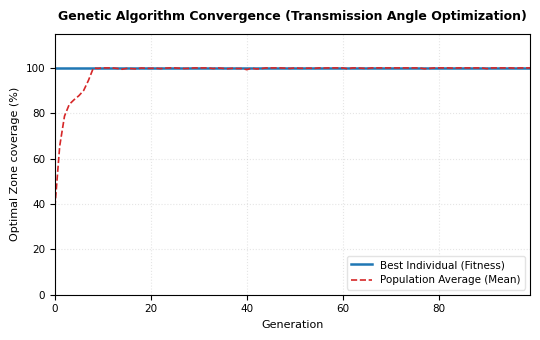

In [3]:
import matplotlib.pyplot as plt
import os
import glob

# --- 4. Automated File Naming System ---
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_1.5_ga_link_length_optimization"
except Exception:
    notebook_name = "Figure_1.5_ga_link_length_optimization"

# --- 2. Springer Quality & Style Configurations ---
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Helvetica', 'Arial']

# Compact single-column figure size for Springer
fig, ax = plt.subplots(figsize=(5.5, 3.5))

# --- Plotting Data ---
ax.plot(best_hist, label='Best Individual (Fitness)', color='#1f77b4', linewidth=1.8)
ax.plot(mean_hist, label='Population Average (Mean)', color='#d62728', linestyle='--', linewidth=1.2)

# --- 3. Strict Anti-Overlap & Aesthetic Tuning ---
ax.set_title('Genetic Algorithm Convergence (Transmission Angle Optimization)', fontsize=9, fontweight='bold', pad=10)
ax.set_xlabel('Generation', fontsize=8)
ax.set_ylabel('Optimal Zone coverage (%)', fontsize=8)

# Clean, discrete grid lines
ax.grid(True, linestyle=':', alpha=0.5, color='#cccccc')

# Tick formatting
ax.tick_params(axis='both', which='major', labelsize=7.5)

# Expand limits dynamically to ensure margin safety
ax.set_xlim(0, len(best_hist) - 1)
ax.set_ylim(0, 115) # Extended limit to prevent legend/data collision

# Non-obstructive legend placement
ax.legend(loc='lower right', fontsize=7.5, frameon=True, framealpha=0.9, edgecolor='#e0e0e0')

# --- 5. Mandatory Double Export ---
plt.tight_layout()
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()